# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: 1006435854 <br>
**Nombre**: Axl Daniel Anzola Ortiz <br>
**Correo** axl.anzola.5854@miremington.edu.co

# Taller #1 - Encuesta TV

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA)** sobre una encuesta de hábitos de televisión: quién ve qué, cuántas horas y cuánto paga por sus suscripciones. Lo harás con las dos librerías base del ecosistema de ciencia de datos en Python: **Pandas** (manipulación de tablas) y **Matplotlib** (gráficos).

### Alcance

Al terminar serás capaz de:

1. Inspeccionar un conjunto de datos nuevo (tamaño, tipos, valores faltantes).
2. Filtrar, contar, agrupar y ordenar con operaciones *vectorizadas* (sin recorrer filas con `for`).
3. Elegir y construir el gráfico adecuado para cada tipo de pregunta.
4. Contrastar hipótesis simples (¿hay diferencia entre hombres y mujeres?) y detectar *outliers*.
5. **Comunicar con honestidad** lo que los datos permiten (y no permiten) concluir.

## 1. Contexto del problema

Imagina que trabajas para un canal regional o una plataforma de *streaming* que quiere entender mejor a su audiencia. Se aplicó una encuesta corta a **68 personas** y la gerencia quiere respuestas a preguntas como:

- ¿Quiénes son los encuestados (edad, género)?
- ¿Qué canales son los más queridos y **quién los prefiere**? Esto orienta qué contenidos comprar o promocionar.
- ¿Ven más televisión los jóvenes o los adultos? Esto orienta **en qué franja** y con qué formato publicar.
- ¿Cuánto pagan por sus suscripciones y **qué tipo de persona paga más**? Esto orienta la política de precios.

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*: un análisis exploratorio revela errores en los datos, patrones y preguntas nuevas, y evita construir modelos sobre supuestos falsos.

### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `nombre` | Nombre del encuestado | texto |
| `edad` | Edad en años | entero |
| `genero` | `M` (masculino) o `F` (femenino) | categórica |
| `canal_fav1`, `canal_fav2`, `canal_fav3` | Primer, segundo y tercer canal favorito | texto |
| `horas` | Horas de consumo de TV (horas x día) | entero |
| `costo_mes` | Costo mensual de suscripciones (pesos colombianos) | entero |

## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.

In [ ]:
# 1) Descarga el archivo y lo guarda como encuesta_tv.csv (en Colab/Jupyter, el "!" ejecuta un comando de consola)
!wget --no-verbose -O encuesta_tv.csv https://paste.c-net.org/WimpsPaolo

2026-11-21 02:50:32 URL:https://paste.c-net.org/WimpsPaolo [3134/3134] -> "encuesta_tv.csv" [1]


In [ ]:
# 2) Importamos las librerías con sus alias convencionales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 3) Cargamos el CSV. OJO: el separador NO es coma, es una barra vertical "|"
df = pd.read_csv('encuesta_tv.csv', sep='|')

> **Teoría — separadores.** `read_csv` asume por defecto que las columnas están separadas por coma. Si el archivo usa otro carácter y no lo indicas con `sep=`, obtendrás **una sola columna** con todo pegado. Si te ocurre, ese es el primer sospechoso.

> **Alternativa sin `wget`:** `pd.read_csv('https://paste.c-net.org/WimpsPaolo', sep='|')` lee directamente desde la URL.

## Parte 1 — Primer contacto con los datos (Pasos 1–4)

> **Teoría.** Antes de calcular nada, un analista responde tres preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos y nulos) y *¿cómo se ve?* (muestras del inicio **y** del final; el final puede revelar registros agregados más tarde con otro formato).


### Paso 1. ¿Cuántos registros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una *tupla* `(filas, columnas)`.

In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape

(68, 8)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` resume nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.

In [ ]:
df.info()
# Pista: info() es un MÉTODO (sí lleva paréntesis) e imprime directamente.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   nombre      68 non-null     object
 1   edad        68 non-null     int64 
 2   genero      68 non-null     object
 3   canal_fav1  68 non-null     object
 4   canal_fav2  68 non-null     object
 5   canal_fav3  67 non-null     object
 6   horas       68 non-null     int64 
 7   costo_mes   68 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 4.4+ KB


### Paso 3. Muestra las primeras 10 filas de los datos.

In [ ]:
df.head(10)
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.


,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
1,jennifer,18,F,Caracol,RCN,Netflix,8,18000
2,julián,33,M,CNN,Star+,Disney+,5,23000
3,luisa,25,F,RCN,Caracol,Cinemax,6,15000
4,marcelo,16,M,Boomerang,Cartoon Network,Disney+,9,20000
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000
6,stephany,11,F,Disney+,Star+,Amazon Prime,6,19000
7,mariana,32,F,Star+,HBO+,Paramount+,4,21000
8,juan,28,M,Fox,HBO+,Netflix,7,22000
9,andrea,20,F,Caracol,RCN,Netflix,5,19000


### Paso 4. Muestra las últimas 10 filas de los datos.

In [ ]:
# Muestra las 10 últimas filas.
# Pista: es el método "hermano" de head().
df.tail(10)


,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
58,paola,25,F,ESPN,ESPN2,Fox Sports,4,21000
59,juanita maria,34,F,HBO+,Netflix,Amazon Prime,6,23000
60,carlos andres,32,M,CNN,BBC,Discovery,5,24000
61,lina,23,F,HBO+,Netflix,Amazon Prime,7,20000
62,felipe andres,35,M,ESPN,ESPN2,Fox Sports,6,22000
63,maria,26,F,Netflix,HBO+,Disney+,5,21000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000
65,juliana,24,F,ESPN,ESPN2,Fox Sports,4,22000
66,pablo,37,M,HBO+,Netflix,Amazon Prime,6,23000
67,juana,29,F,CNN,BBC,Discovery,5,21000


### Evaluación — Parte 1

- **E1.1 (conceptual).** En la salida de `info()` una columna muestra menos valores no nulos que las demás. ¿Cuál es y qué significa?

 **R//** La columna con menos valores no nulos corresponde a los canales favoritos (por ejemplo, canal_fav2 o canal_fav3 si algún encuestado solo indicó uno o dos canales). Significa que hay datos faltantes (NaN / valores vacíos) en esas filas.

- **E1.2 (conceptual).** ¿Por qué `df.shape` se escribe sin paréntesis y `df.info()` con ellos?

**R//** df.shape es un atributo que guarda directamente las dimensiones (filas, columnas) del DataFrame, por lo que no se llama como función. df.info() es un método (una función del objeto) que ejecuta un proceso para inspeccionar e imprimir el resumen de la tabla.

- **E1.3 (código).** Obtén de una sola vez las estadísticas descriptivas (conteo, media, desviación, mínimo, cuartiles, máximo) de las columnas numéricas.

In [ ]:
# Reto E1.3 — Pista: existe un método cuyo nombre en inglés significa "describir".
df.describe()


,edad,horas,costo_mes
count,68.000000,68.000000,68.000000
mean,29.882353,6.102941,21470.588235
std,11.033909,1.497657,2215.754905
min,11.000000,4.000000,15000.000000
25%,21.750000,5.000000,20000.000000
50%,29.000000,6.000000,22000.000000
75%,37.000000,7.000000,23000.000000
max,53.000000,10.000000,27000.000000


## Parte 2 — Valores únicos, estadísticas y conteos (Pasos 5–8)

> **Teoría.** Tres herramientas que usarás todo el curso:
> - `Serie.unique()` → los valores distintos (como arreglo).
> - `Serie.nunique()` → **cuántos** valores distintos hay (ignora `NaN`).
> - `Serie.value_counts()` → cuántas veces aparece cada valor, ordenado de mayor a menor.


### Paso 5. ¿Cuáles son los nombres únicos de las personas encuestadas?

In [ ]:
# Obtén los nombres distintos de la columna 'nombre'.
# Pista: selecciona la columna con df['nombre'] y aplica el método de valores únicos.
df['nombre'].unique()

array(['orlando', 'jennifer', 'julián', 'luisa', 'marcelo', 'guillermo',
       'stephany', 'mariana', 'juan', 'andrea', 'carlos', 'valentina',
       'diego', 'camila', 'felipe', 'ana', 'oscar', 'natalia', 'daniel',
       'sara', 'luis', 'catalina', 'pedro', 'alejandra', 'rodrigo',
       'laura', 'manuel', 'andres', 'patricia', 'ana maria', 'jose',
       'andres felipe', 'santiago', 'carolina', 'diana', 'andres david',
       'sergio', 'margarita', 'juanita', 'carlos alberto',
       'andrea carolina', 'carlos enrique', 'marcela', 'lucas',
       'patricia andrea', 'pedro jose', 'luis alberto', 'andrea maria',
       'jose luis', 'carla', 'miguel', 'luz', 'juan pablo', 'camilo',
       'andrea patricia', 'roberto', 'claudia', 'alejandro', 'paola',
       'juanita maria', 'carlos andres', 'lina', 'felipe andres', 'maria',
       'juliana', 'pablo', 'juana'], dtype=object)

### Paso 6. ¿Cuántos canales únicos hay y cuáles son?

**Lógica:** los canales están repartidos en **tres columnas**. Para contarlos como un solo conjunto primero hay que *apilar* las tres columnas en una sola Serie con `pd.concat([...])`.


In [ ]:
# 1. Apila canal_fav1, canal_fav2 y canal_fav3 en una sola Serie (guárdala en la variable 'canales').
# 2. Muestra los canales distintos con unique().
# 3. Cuenta cuántos hay con nunique() y compara con len(canales.unique()).


canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']], ignore_index=True)


print(canales.unique())

print("nunique():", canales.nunique())

print("len(unique()):", len(canales.unique()))



['RCN' 'Caracol' 'CNN' 'Boomerang' 'ESPN' 'Disney+' 'Star+' 'Fox'
 'Teleantioquia' 'Warner' 'Netflix' 'HBO+' 'Cartoon Network' 'Disney'
 'Discovery' 'Telepacifico' 'ESPN2' 'TNT' 'BBC' 'Fox Sports' 'NatGeo'
 'Cinemax' 'Amazon Prime' 'Paramount+' 'Sony' 'GolTV' 'Nickelodeon'
 'History' nan]
nunique(): 28
len(unique()): 29


> **Advertencia — `NaN` es un valor.** `unique()` **incluye** el valor faltante (`NaN`) como si fuera un canal; `nunique()` lo ignora. Si cuentas con `len(unique())` obtendrás un canal "fantasma".

### Paso 7. ¿Cuál es el promedio de edad?

In [ ]:
# Calcula la edad promedio.
# Pista: df['edad'] + método de la media.
# Exploración extra: prueba .min(), .max(), .median(), .sum(), .count()

print("Promedio:", df['edad'].mean())
print("Min:", df['edad'].min())
print("Max:", df['edad'].max())
print("Mediana:", df['edad'].median())
print("Suma:", df['edad'].sum())
print("Conteo:", df['edad'].count())


Promedio: 29.88235294117647
Min: 11
Max: 53
Mediana: 29.0
Suma: 2032
Conteo: 68


> Los métodos de resumen de una Serie incluyen `.min()`, `.max()`, `.median()`, `.sum()`, `.count()` y `.value_counts()`. (En el comentario del cuaderno original aparece escrito `values_count`, que **no existe**: el nombre correcto es `value_counts`.)

### Paso 8. ¿Cuántos encuestados son hombres y cuántas mujeres?

Resuelve el conteo de DOS formas.

In [ ]:
# Forma A: value_counts() sobre la columna 'genero'.
df['genero'].value_counts()


,count
genero,
M,35
F,33


In [ ]:
# Forma B: df.groupby('genero') seguido de .size()
df.groupby('genero').size()

,0
genero,
F,33
M,35


### Evaluación — Parte 2

- **E2.1 (conceptual).** En el Paso 6, ¿por qué `len(canales.unique())` y `canales.nunique()` dan resultados distintos? ¿Cuál es la cifra correcta de canales?

**R//** len(canales.unique()) cuenta NaN (valores faltantes) como si fuera un elemento más cuando hay vacíos, mientras que canales.nunique() ignora los NaN por defecto. La cifra correcta de canales distintos es la que entrega canales.nunique().

- **E2.2 (código).** `nombre` tiene menos valores únicos que filas. Encuentra **todas** las filas cuyo nombre está repetido. ¿Son la misma persona?

In [ ]:
# Pista E2.2 -> duplicated(keep=False) marca TODAS las filas repetidas, no solo la segunda aparición.
df[df['nombre'].duplicated(keep=False)].sort_values('nombre')

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
31,andres felipe,15,M,Discovery,NatGeo,History,9,20000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000


Sí es la misma persona


- **E2.3 (código).** Calcula el **porcentaje** de hombres y de mujeres (no la cantidad).

In [ ]:
# Pista E2.3 -> value_counts() tiene un parámetro que devuelve proporciones (multiplica por 100).
df['genero'].value_counts(normalize=True) * 100


,proportion
genero,
M,51.470588
F,48.529412


- **E2.4 (código + conceptual).** Calcula la **mediana** de edad y compárala con la media. ¿Qué te dice la diferencia?

In [ ]:
# Pista E2.4 -> .median()

mediana = df['edad'].median()
media = df['edad'].mean()
print("Mediana:", mediana, "| Media:", media)

Mediana: 29.0 | Media: 29.88235294117647


## Parte 3 — Filtros y rankings de frecuencia (Pasos 9–11)


> **Teoría — filtrado booleano.** Una condición sobre una columna (`df['edad'] >= 18`) produce una Serie de `True/False`, llamada **máscara**. Al pasarla a `df[...]` quedan solo las filas `True`. Se combinan con `&` (y), `|` (o) y `~` (no), **cada condición entre paréntesis**.

### Paso 9. Muestra los nombres de los hombres mayores de edad

In [ ]:
# 1. Crea la máscara 'filtro' combinando (genero == 'M') y (edad >= 18) con &.
filtro = (df['genero'] == 'M') & (df['edad'] >= 18)

In [ ]:
# 2. Aplica la máscara a df y muestra solo la columna 'nombre'.
df.loc[filtro, 'nombre']

,nombre
0,orlando
2,julián
5,guillermo
8,juan
10,carlos
12,diego
14,felipe
16,oscar
18,daniel
20,luis


> **Antipatrón — no recorras filas con `for`.** El cuaderno original muestra una versión con `df.iterrows()` y la marca como lo que **NO** se debe hacer: obliga a Python a procesar fila por fila, mientras que la máscara booleana opera sobre toda la columna en código compilado. Con 68 filas no notarás la diferencia; con 10 millones, sí.

In [ ]:
# Esto es lo que NO se debe hacer, no es optimo! obliga a usar filas:
for index, datos in df[['nombre', 'genero', 'edad']].iterrows():
    if datos.genero == 'M' and datos.edad >= 18:
        print(datos.nombre)

orlando
julián
guillermo
juan
carlos
diego
felipe
oscar
daniel
luis
pedro
rodrigo
jose
sergio
carlos alberto
carlos enrique
pedro jose
luis alberto
jose luis
miguel
juan pablo
camilo
roberto
alejandro
carlos andres
felipe andres
andres felipe
pablo


### Paso 10. ¿Cuáles son los 3 canales favoritos más comunes?

In [ ]:
# 1. Apila las tres columnas de canales (como en el Paso 6).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']], ignore_index=True)

In [ ]:
# 2. Cuenta la frecuencia de cada canal con value_counts().
frecuencias_canales = canales.value_counts()
frecuencias_canales

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14
Fox Sports,14
Amazon Prime,14
Disney+,10
ESPN2,9
Discovery,8


In [ ]:
# 3. Quédate con los 3 primeros con head(3).
frecuencias_canales.head(3)

,count
HBO+,25
Netflix,21
RCN,15


### Paso 11. ¿Cuál es el canal favorito (`canal_fav1`) más popular entre hombres y entre mujeres?

In [ ]:
# Agrupa por 'genero', toma la columna 'canal_fav1' y cuenta con value_counts().
# Pista: df.groupby(...)[...].value_counts()
# Reto extra: muestra solo los 3 primeros de cada género (investiga .groupby(level=0).head(3)).
conteo_genero_fav1 = df.groupby('genero')['canal_fav1'].value_counts()
print(conteo_genero_fav1)

print("\nTop 3 por género:")
print(conteo_genero_fav1.groupby(level=0).head(3))

genero  canal_fav1     
F       HBO+                9
        Caracol             5
        CNN                 4
        Netflix             3
        RCN                 3
        ESPN                2
        Teleantioquia       2
        Disney              1
        Disney+             1
        Star+               1
        Telepacifico        1
        Warner              1
M       ESPN               12
        HBO+                5
        Cartoon Network     4
        CNN                 3
        RCN                 3
        Discovery           2
        Fox                 2
        Boomerang           1
        Caracol             1
        Netflix             1
        Warner              1
Name: count, dtype: int64

Top 3 por género:
genero  canal_fav1     
F       HBO+                9
        Caracol             5
        CNN                 4
M       ESPN               12
        HBO+                5
        Cartoon Network     4
Name: count, dtype: int64


### Evaluación — Parte 3

- **E3.1 (conceptual).** ¿Por qué en el Paso 9 se escribe `&` y no `and`, y por qué cada condición va entre paréntesis?

**R//** En Pandas se usa & en lugar de and porque & evalúa elemento por elemento sobre Series booleanas, mientras que and espera una sola expresión booleana y genera error con Series. Cada condición va entre paréntesis porque & tiene mayor precedencia que los operadores de comparación (==, >=).



- **E3.2 (código).** ¿Cuántas **mujeres menores de edad** hay y cómo se llaman?


In [ ]:
mujeres_menores = df[(df['genero'] == 'F') & (df['edad'] < 18)]
print("Cantidad:", len(mujeres_menores))
print(mujeres_menores['nombre'])

Cantidad: 3
6      stephany
29    ana maria
38      juanita
Name: nombre, dtype: object


- **E3.3 (código + conceptual).** Muestra el **top 5** de canales del Paso 10. ¿Qué observas en el tercer puesto? ¿Qué problema crea `head(3)`?


In [ ]:
canales.value_counts().head(5)

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14


El problema de head(3) es que corta en los 3 primeros registros y puede ocultar canales empatados con el tercer lugar.

como en este caso se observa el puesto 3 con el mismo resultado que el puesto 4


- **E3.4 (código).** El Paso 11 solo mira `canal_fav1`. Repite el análisis considerando **los tres** canales favoritos. *Pista:* `df.melt(id_vars='genero', value_vars=[...], value_name='canal')` convierte tres columnas en una sola columna larga. ¿Cambia la conclusión?

In [ ]:
largo = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
).dropna(subset=['canal'])

largo.groupby('genero')['canal'].value_counts().groupby(level=0).head(3)

genero  canal     
F       HBO+          16
        Netflix       14
        Caracol       11
M       ESPN          13
        Fox Sports    12
        HBO+           9
Name: count, dtype: int64

## Parte 4 — Relaciones entre variables y extremos (Pasos 12–14)

> **Teoría — correlación de Pearson.** `Serie_a.corr(Serie_b)` mide la **relación lineal** entre dos variables numéricas, entre −1 y +1:
> - cercana a **+1**: cuando una sube, la otra tiende a subir;
> - cercana a **−1**: cuando una sube, la otra tiende a bajar;
> - cercana a **0**: *no hay relación lineal* (¡pero puede haber otra forma de relación!).
>
> **Correlación no implica causalidad.**


### Paso 12. ¿Hay relación entre la edad y las horas de consumo de TV?

In [ ]:
# Calcula el coeficiente de correlación entre 'edad' y 'horas'.
# Interpreta el valor en una línea de comentario: ¿fuerte, débil, nula?
corr_edad_horas = df['edad'].corr(df['horas'])
print(corr_edad_horas)


-0.027255358787632557


### Paso 13. ¿Cuál es el costo promedio mensual de suscripciones?

In [ ]:
# Calcula el promedio de la columna 'costo_mes'.
df['costo_mes'].mean()



np.float64(21470.58823529412)

### Paso 14. ¿Cuál es el encuestado más joven y cuál el de mayor edad?

**Lógica:** no basta con el valor mínimo; queremos **quién** es. `idxmin()` / `idxmax()` devuelven la *etiqueta de la fila* donde ocurre el mínimo/máximo, y con `.loc[...]` recuperas esa fila completa.


In [ ]:
# Encuentra la fila del más joven y la fila del mayor.
# Pista: df.loc[df['edad'].idxmin()]  y  df.loc[df['edad'].idxmax()]
# Alternativa: df.sort_values('edad') y mira la primera y la última fila.
print("Más joven:")
print(df.loc[df['edad'].idxmin()])

print("\nMayor edad:")
print(df.loc[df['edad'].idxmax()])

Más joven:
nombre            stephany
edad                    11
genero                   F
canal_fav1         Disney+
canal_fav2           Star+
canal_fav3    Amazon Prime
horas                    6
costo_mes            19000
Name: 6, dtype: object

Mayor edad:
nombre         jose luis
edad                  53
genero                 M
canal_fav1          ESPN
canal_fav2    Fox Sports
canal_fav3           NaN
horas                 10
costo_mes          27000
Name: 48, dtype: object


### Evaluación — Parte 4

- **E4.1 (conceptual).** Si en el Paso 12 obtuviste una correlación cercana a 0, ¿puedes afirmar que la edad **no influye** en las horas de TV? Justifica.


**R//** No, una correlación cercana a 0 solo indica ausencia de relación lineal (y correlación tampoco implica causalidad). Podría existir una relación no lineal o diferencias por grupos de edad que no se captan con una línea recta.

- **E4.2 (código).** Verifica tu respuesta anterior: compara el promedio de horas de los **menores de 18** contra los **adultos**. *Pista:* `df.groupby(df['edad'] < 18)['horas'].mean()`.


In [ ]:
df.groupby(df['edad'] < 18)['horas'].mean()

,horas
edad,
False,5.87931
True,7.40000


- **E4.3 (código).** Calcula la correlación entre `edad` y `costo_mes`. ¿Qué tan fuerte es?


In [ ]:
corr_costo = df['edad'].corr(df['costo_mes'])
print("Correlación edad vs costo_mes:", corr_costo)

# Interpretación (E4.3): r ≈ 0.65 indica una correlación lineal positiva moderada-fuerte;
# a mayor edad, tiende a aumentar el gasto mensual en suscripciones.

Correlación edad vs costo_mes: 0.6500215115262994


- **E4.4 (código).** Obtén la edad mínima y máxima **por género** en una sola instrucción (`groupby` + `agg`).


In [ ]:
df.groupby('genero')['edad'].agg(['min', 'max'])


,min,max
genero,,
F,11,51
M,12,53


## Parte 5 — Visualización básica (Pasos 15–18)

> **Teoría — ¿qué gráfico para qué pregunta?**
>
> | Pregunta | Gráfico |
> |---|---|
> | Cuántos hay en cada categoría | Barras |
> | Qué parte del total es cada categoría (pocas categorías) | Pie / torta |
> | Cómo se distribuye una variable numérica | Barras sobre conteos o histograma |
> | Cómo se relacionan dos variables numéricas | Dispersión (*scatter*) |
> | Composición dentro de cada categoría | Barras apiladas |
>
> **Regla de oro:** todo gráfico lleva **título**, **etiquetas de ejes** y, si hay varias series, **leyenda**.


### Paso 15. Gráfico de barras: distribución de edades

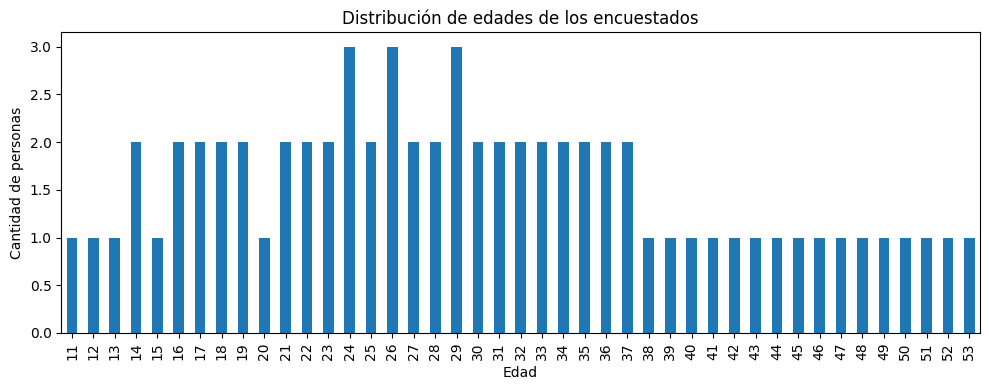

In [ ]:
# 1. Cuenta cuántas personas hay de cada edad (value_counts) y ordena por edad (sort_index).
conteo_edad = df['edad'].value_counts().sort_index()
# 2. Grafica con .plot(kind='bar').
conteo_edad.plot(kind='bar', figsize=(10, 4))
# 3. Añade título y etiquetas de ejes con plt.title(), plt.xlabel(), plt.ylabel().
plt.title('Distribución de edades de los encuestados')
plt.xlabel('Edad')
plt.ylabel('Cantidad de personas')
# 4. Cierra con plt.show().
plt.tight_layout()
plt.show()

### Paso 16. Gráfico de pie: distribución de géneros


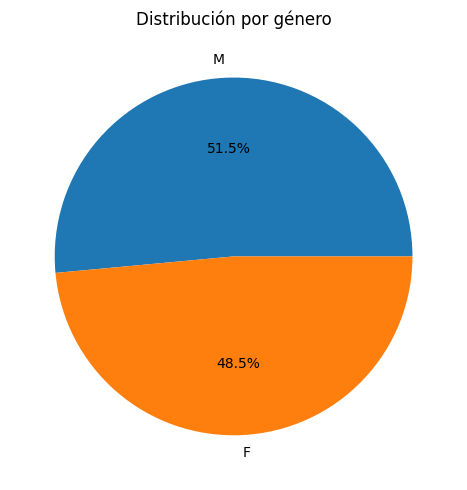

In [ ]:
# Usa los conteos de género y grafica con .plot(kind='pie', autopct='%1.1f%%')
# (autopct imprime el porcentaje sobre cada porción). Agrega un título.
df['genero'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5))
plt.title('Distribución por género')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Paso 17. Barras apiladas: los 3 canales favoritos por género

**Lógica:** necesitas una tabla con canales en las filas y géneros en las columnas (`pd.crosstab`), restringida a los 3 canales más frecuentes, y luego graficarla con `stacked=True`.


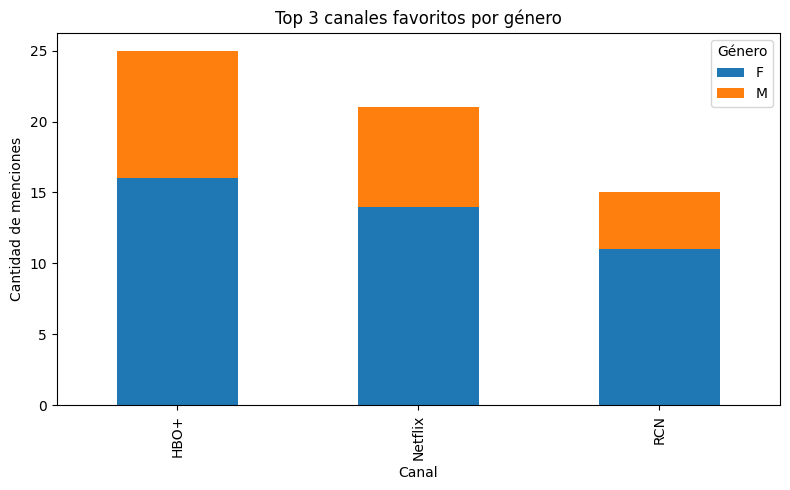

In [ ]:
# 1. Convierte las 3 columnas de canales en una sola columna larga con df.melt(...) (como en E3.4).
largo = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
).dropna(subset=['canal'])
# 2. Determina los 3 canales más frecuentes.
top3 = largo['canal'].value_counts().head(3).index
# 3. Construye la tabla con pd.crosstab(largo['canal'], largo['genero']) y filtra esos 3 con .loc[...].
tabla = pd.crosstab(largo['canal'], largo['genero']).loc[top3]
# 4. Grafica con .plot(kind='bar', stacked=True) y agrega título y etiquetas.
tabla.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Top 3 canales favoritos por género')
plt.xlabel('Canal')
plt.ylabel('Cantidad de menciones')
plt.legend(title='Género')
plt.tight_layout()
plt.show()


### Paso 18. Dispersión: edad vs. horas de consumo de TV


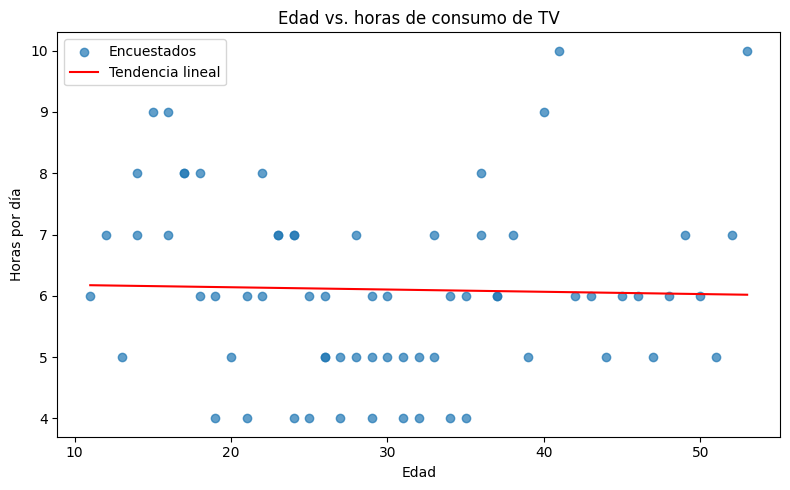

In [ ]:
# 1. Usa plt.scatter(x, y) con x = edad e y = horas (alpha=0.7 ayuda cuando los puntos se superponen).
x = df['edad']
y = df['horas']
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.7, label='Encuestados')
# 2. Reto extra: dibuja la línea de tendencia con np.polyfit(x, y, 1) y plt.plot(...).
m, b = np.polyfit(x, y, 1)
plt.plot(np.sort(x), m * np.sort(x) + b, color='red', label='Tendencia lineal')

plt.title('Edad vs. horas de consumo de TV')
plt.xlabel('Edad')
plt.ylabel('Horas por día')
plt.legend()
plt.tight_layout()
plt.show()

### Evaluación — Parte 5

- **E5.1 (conceptual).** El gráfico del Paso 15 tiene muchas barras muy delgadas (una por cada edad distinta). ¿Qué gráfico resumiría mejor la distribución y por qué?


Un histograma (o agrupar edades en rangos), porque agrupa los datos en intervalos y muestra con mayor claridad la distribución general sin fragmentar en barras muy delgadas para cada edad individual.

- **E5.2 (conceptual).** ¿En qué situaciones un gráfico de pie es mala idea?


Cuando hay muchas categorías, cuando los valores son muy similares entre sí o cuando se necesita comparar cantidades exactas con precisión (las barras suelen ser más legibles).

- **E5.3 (código).** Construye un histograma de `horas`.


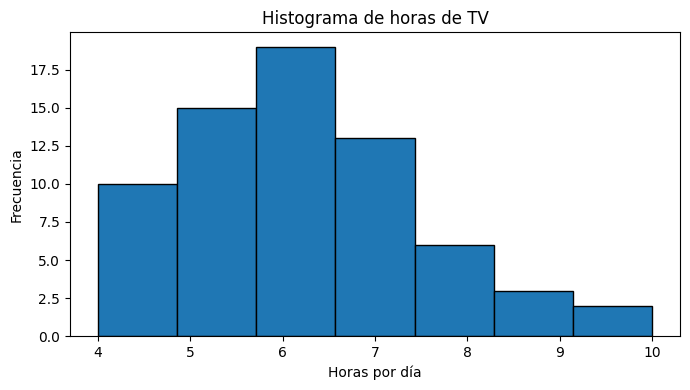

In [ ]:
# Reto E5.3 — Pista: .plot(kind='hist', bins=7)  o  plt.hist(...)
df['horas'].plot(kind='hist', bins=7, edgecolor='black', figsize=(7, 4))
plt.title('Histograma de horas de TV')
plt.xlabel('Horas por día')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

- **E5.4 (conceptual).** Mirando el gráfico del Paso 17: ¿qué canal de los tres tiene más aficionadas que aficionados? ¿Y la relación sigue igual para todos?


Observando el gráfico del Paso 17, identifica cuál de los 3 canales tiene mayor segmento de mujeres (F) que de hombres (M) y comprueba si ese mismo comportamiento se repite en los otros dos canales o cambia según el canal.

## Parte 6 — Rankings y agrupaciones (Pasos 19, 20, 22, 23)

> **Teoría — tres patrones muy frecuentes.**
> 1. **Ranking:** `df.nlargest(n, 'col')` / `df.nsmallest(n, 'col')` (equivale a ordenar y tomar los primeros).
> 2. **Discretizar:** `pd.cut(serie, bins=[...], labels=[...])` convierte una variable numérica en **grupos por rangos**. Los intervalos son **cerrados a la derecha**: `(9, 20]` incluye el 20 y excluye el 9.
> 3. **Agrupar y resumir:** `df.groupby('grupo')['col'].mean()`.


### Paso 19. Los 5 encuestados con mayor costo mensual (y grafícalos)


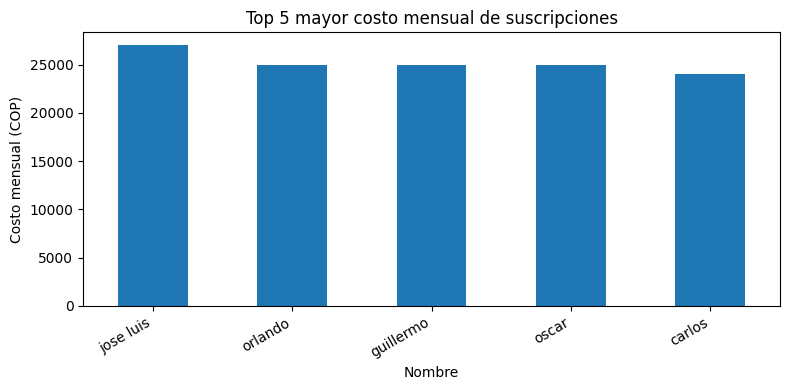

In [ ]:
# 1. Obtén las 5 filas con mayor 'costo_mes' usando nlargest.
top5_costo = df.nlargest(5, 'costo_mes')
# 2. Grafica un diagrama de barras con los nombres en el eje x y el costo en el eje y.
top5_costo.plot(x='nombre', y='costo_mes', kind='bar', legend=False, figsize=(8, 4))
plt.title('Top 5 mayor costo mensual de suscripciones')
plt.xlabel('Nombre')
plt.ylabel('Costo mensual (COP)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


### Paso 20. Costo promedio mensual por grupo de edad (10-20, 21-30, ...)


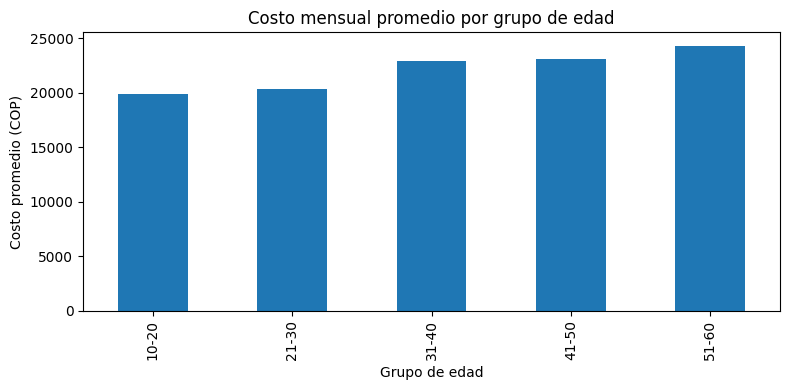

In [ ]:
# 1. Define los límites de los grupos (bins) y sus etiquetas. Pista: bins = [9, 20, 30, 40, 50, 60]
bins = [9, 20, 30, 40, 50, 60]
labels = ['10-20', '21-30', '31-40', '41-50', '51-60']
# 2. Crea la columna 'grupo_edad' con pd.cut.
df['grupo_edad'] = pd.cut(df['edad'], bins=bins, labels=labels)
# 3. Calcula el costo promedio por grupo con groupby(...)['costo_mes'].mean()
#    (usa observed=True para evitar un aviso de Pandas con categorías).
prom_grupo = df.groupby('grupo_edad', observed=True)['costo_mes'].mean()
# 4. Grafícalo como barras.
prom_grupo.plot(kind='bar', figsize=(8, 4))
plt.title('Costo mensual promedio por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Costo promedio (COP)')
plt.tight_layout()
plt.show()

### Paso 22. Los 3 canales más populares entre los de 30 años o más

> Agregar bloque entrecomillado




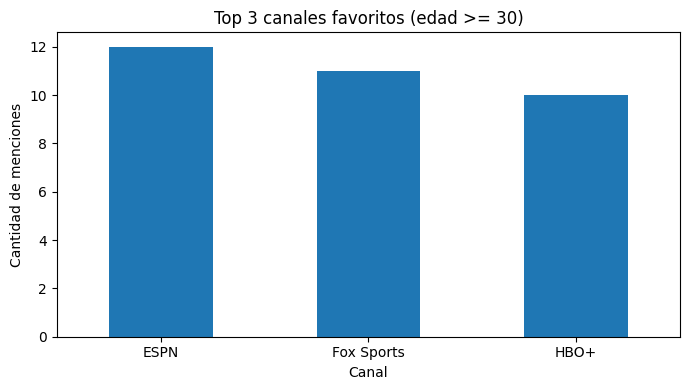

In [ ]:
# 1. Filtra df para quedarte con edad >= 30.
df_30 = df[df['edad'] >= 30]
# 2. Apila sus tres columnas de canales y cuenta con value_counts().
canales_30 = pd.concat(
    [df_30['canal_fav1'], df_30['canal_fav2'], df_30['canal_fav3']],
    ignore_index=True
).dropna()
conteo_30 = canales_30.value_counts()
# 3. Toma el top 3 y grafícalo.

top3_30 = conteo_30.head(3)
top3_30.plot(kind='bar', figsize=(7, 4))
plt.title('Top 3 canales favoritos (edad >= 30)')
plt.xlabel('Canal')
plt.ylabel('Cantidad de menciones')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Paso 23. Barras horizontales: los 5 encuestados con más horas de TV


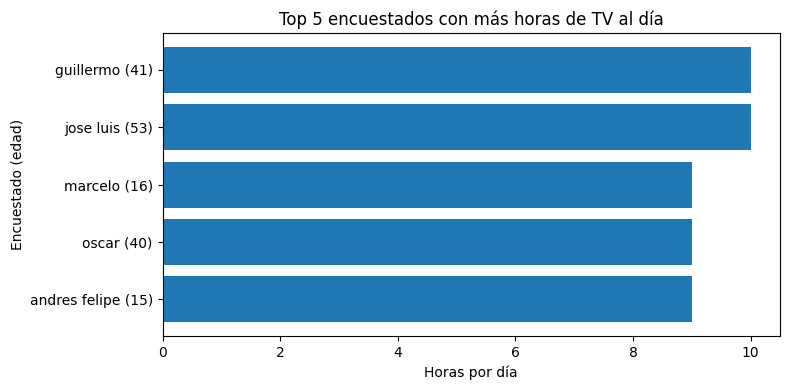

In [ ]:
# 1. Obtén las 5 filas con más 'horas' (nlargest).
top5_horas = df.nlargest(5, 'horas').iloc[::-1]
# 2. Grafica con plt.barh(etiquetas, valores).
# 3. Reto: usa "nombre (edad)" como etiqueta; luego verás por qué (ver E6.3).
#    Pista: top5['nombre'] + ' (' + top5['edad'].astype(str) + ')'

etiquetas = top5_horas['nombre'] + ' (' + top5_horas['edad'].astype(str) + ')'

plt.figure(figsize=(8, 4))
plt.barh(etiquetas, top5_horas['horas'])
plt.title('Top 5 encuestados con más horas de TV al día')
plt.xlabel('Horas por día')
plt.ylabel('Encuestado (edad)')
plt.tight_layout()
plt.show()

### Evaluación — Parte 6

- **E6.1 (conceptual + código).** En el Paso 19, ¿qué ocurre con el 5.º lugar? Cuenta cuántas personas pagan lo mismo que quien quedó en el 5.º puesto. Investiga el parámetro `keep='all'` de `nlargest`.


Si hay empates en el 5.º lugar, `nlargest(5, 'costo_mes')` corta en 5 filas y deja fuera a quienes empatan ese monto, mientras que `keep='all'` incluye a todas las personas empatadas en el 5.º puesto.

In [ ]:
quinto_valor = df.nlargest(5, 'costo_mes')['costo_mes'].iloc[-1]
empatados_5to = df.nlargest(5, 'costo_mes', keep='all')
print("Valor del 5.º lugar:", quinto_valor)
print("Personas con exactamente ese costo:", (df['costo_mes'] == quinto_valor).sum())
print(empatados_5to[['nombre', 'edad', 'costo_mes']])

Valor del 5.º lugar: 24000
Personas con exactamente ese costo: 9
            nombre  edad  costo_mes
48       jose luis    53      27000
0          orlando    35      25000
5        guillermo    41      25000
16           oscar    40      25000
10          carlos    37      24000
18          daniel    30      24000
24         rodrigo    38      24000
33        carolina    44      24000
37       margarita    47      24000
41  carlos enrique    49      24000
46    luis alberto    52      24000
55         roberto    33      24000
60   carlos andres    32      24000


- **E6.2 (código).** ¿Cuántas personas hay en cada grupo de edad del Paso 20? ¿Por qué importa saberlo antes de interpretar los promedios?


In [ ]:
print(df.groupby('grupo_edad', observed=True).size())

grupo_edad
10-20    15
21-30    23
31-40    17
41-50    10
51-60     3
dtype: int64


- **E6.3 (conceptual).** En el Paso 23 aparece el nombre `andres felipe`. ¿Qué problema puede causar usar `nombre` como etiqueta?


Usar nombre como etiqueta puede causar ambigüedad si hay nombres repetidos o escritos sin mayúsculas/incompletos (como andres felipe), además de solaparse si son largos o exponer datos identificables.

- **E6.4 (conceptual).** El costo promedio crece con el grupo de edad. ¿Puedes concluir que "envejecer hace que la gente gaste más en suscripciones"? Relaciónalo con E4.3.


No se puede concluir que envejecer cause mayor gasto en suscripciones. Aunque la correlación entre edad y costo_mes fue positiva (~0.65 en E4.3), es un dato observacional y transversal: la edad puede estar asociada a otras variables como mayor ingreso, estabilidad laboral o tamaño del hogar.   

## Parte 7 — Análisis crítico: diferencias, asociaciones y outliers (Pasos 21, 24, 25)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* y si es *justo* compararlo.

> **Teoría — prueba de hipótesis en una línea.** Para comparar dos grupos se plantea:
> - **H₀:** no hay diferencia real entre los grupos (lo observado es azar).
> - **H₁:** sí hay diferencia.
>
> La prueba entrega un **p-valor**: la probabilidad de observar una diferencia *al menos tan grande* si H₀ fuera cierta. Si `p < 0.05` (nivel de significancia habitual) se rechaza H₀. **Un p-valor pequeño no dice que la diferencia sea importante, solo que es poco probable que sea azar.**


### Paso 21. ¿Hay diferencias significativas en el costo mensual entre hombres y mujeres?


                mean          std  count
genero                                  
F       20393.939394  2060.633912     33
M       22485.714286  1868.806297     35


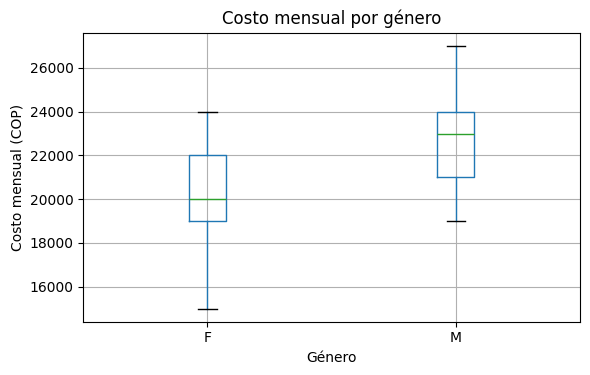

Estadístico t: 4.3764 | p-valor: 0.0000


In [ ]:
from scipy import stats

# 1. Calcula media, desviación y cantidad de 'costo_mes' por género (groupby + agg).
print(df.groupby('genero')['costo_mes'].agg(['mean', 'std', 'count']))

# 2. Dibuja un diagrama de cajas por género: df.boxplot(column='costo_mes', by='genero')
df.boxplot(column='costo_mes', by='genero', figsize=(6, 4))
plt.title('Costo mensual por género')
plt.suptitle('')
plt.xlabel('Género')
plt.ylabel('Costo mensual (COP)')
plt.tight_layout()
plt.show()

# 3. Separa los costos en dos Series (hombres y mujeres).
hombres_costo = df.loc[df['genero'] == 'M', 'costo_mes'].dropna()
mujeres_costo = df.loc[df['genero'] == 'F', 'costo_mes'].dropna()

# 4. Aplica la prueba t de Welch:
t_stat, p_val = stats.ttest_ind(hombres_costo, mujeres_costo, equal_var=False)
print(f"Estadístico t: {t_stat:.4f} | p-valor: {p_val:.4f}")

# 5. Escribe en un comentario tu conclusión usando el p-valor.
# Conclusión: si p < 0.05 se rechaza H0 (hay diferencia estadísticamente significativa en el costo promedio);
# si p >= 0.05 no hay evidencia suficiente para afirmar una diferencia real entre géneros.

### Paso 24. ¿Hay relación entre el género y los canales favoritos?

**Lógica:** una tabla de contingencia (`pd.crosstab`) cuenta cuántos hombres y mujeres eligieron cada canal. Si el género no importara, la proporción hombre/mujer sería parecida en todos los canales.


In [ ]:
# 1. Pasa los tres canales a formato largo con df.melt(...) y elimina los vacíos con .dropna(subset=['canal']).
largo_canales = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
).dropna(subset=['canal'])
# 2. Construye la tabla de contingencia canal x género.
tabla_cg = pd.crosstab(largo_canales['canal'], largo_canales['genero'])
# 3. Ordénala por total y observa los 10 canales más frecuentes.
tabla_cg['total'] = tabla_cg.sum(axis=1)
tabla_cg = tabla_cg.sort_values('total', ascending=False)
print(tabla_cg.head(10))
# 4. (Opcional) Prueba chi-cuadrado: stats.chi2_contingency(tabla)

genero         F   M  total
canal                      
HBO+          16   9     25
Netflix       14   7     21
ESPN           2  13     15
RCN           11   4     15
Fox Sports     2  12     14
Amazon Prime   9   5     14
Caracol       11   3     14
Disney+        4   6     10
ESPN2          2   7      9
Discovery      4   4      8


> **Advertencia — chi-cuadrado con muestras pequeñas.** Esa prueba exige conteos esperados razonablemente grandes por celda. Con 28 canales y 68 personas, muchas celdas quedan casi vacías: toma el p-valor como **orientación exploratoria**, no como veredicto.


### Paso 25. Outliers en `horas` y `costo_mes` y su impacto

> **Teoría — dos reglas para detectar outliers.**
> - **Regla IQR:** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`. Es la regla que dibuja los "bigotes" del boxplot.
> - **Regla z:** `z = (x − media) / desviación`. Se sospecha de `|z| > 2` (o 3 en muestras grandes).
>
> *Atípico no significa erróneo.* Antes de eliminar, pregunta si es un error de captura o un caso real.


Outliers IQR en horas:
Empty DataFrame
Columns: [nombre, edad, genero, horas]
Index: []

Outliers IQR en costo_mes:
  nombre  edad genero  costo_mes
3  luisa    25      F      15000

Outliers |z| > 2 en horas:
       nombre  horas
5   guillermo     10
48  jose luis     10

Outliers |z| > 2 en costo_mes:
       nombre  costo_mes
3       luisa      15000
48  jose luis      27000


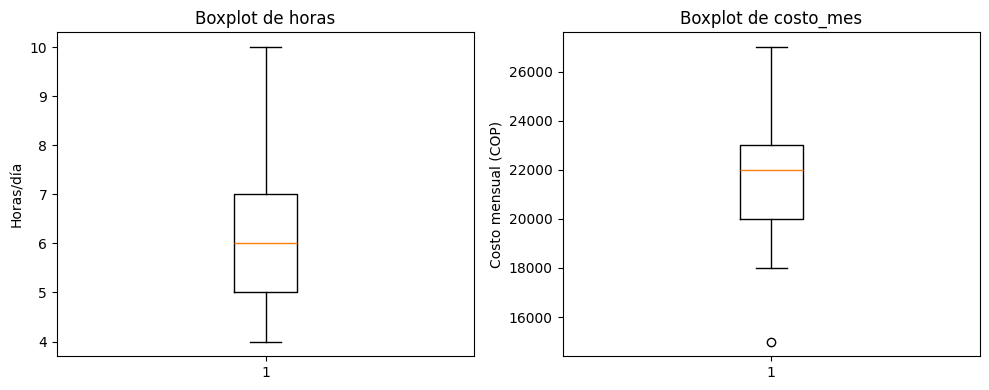

Original costo_mes -> media: 21470.58823529412 | std: 2215.754904782675
Sin outliers IQR -> media: 21567.16417910448 | std: 2083.294888835697


In [ ]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana con la regla IQR (use serie.quantile([0.25, 0.75])).
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return (serie < lim_inf) | (serie > lim_sup)
# 2. Aplícala a 'horas' y a 'costo_mes' y muestra quiénes son los atípicos.
mask_horas_iqr = outliers_iqr(df['horas'])
mask_costo_iqr = outliers_iqr(df['costo_mes'])
print("Outliers IQR en horas:")
print(df.loc[mask_horas_iqr, ['nombre', 'edad', 'genero', 'horas']])

print("\nOutliers IQR en costo_mes:")
print(df.loc[mask_costo_iqr, ['nombre', 'edad', 'genero', 'costo_mes']])
# 3. Repite con la regla z.
z_horas = (df['horas'] - df['horas'].mean()) / df['horas'].std()
z_costo = (df['costo_mes'] - df['costo_mes'].mean()) / df['costo_mes'].std()

print("\nOutliers |z| > 2 en horas:")
print(df.loc[z_horas.abs() > 2, ['nombre', 'horas']])

print("\nOutliers |z| > 2 en costo_mes:")
print(df.loc[z_costo.abs() > 2, ['nombre', 'costo_mes']])

# 4. Dibuja un boxplot de cada variable (dos subgráficos con plt.subplots(1, 2)).
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df['horas'].dropna())
axes[0].set_title('Boxplot de horas')
axes[0].set_ylabel('Horas/día')

axes[1].boxplot(df['costo_mes'].dropna())
axes[1].set_title('Boxplot de costo_mes')
axes[1].set_ylabel('Costo mensual (COP)')

plt.tight_layout()
plt.show()

# 5. Mide el impacto: compara la media y la desviación de 'costo_mes' con y sin los atípicos.
print("Original costo_mes -> media:", df['costo_mes'].mean(), "| std:", df['costo_mes'].std())
sin_iqr = df.loc[~mask_costo_iqr, 'costo_mes']
print("Sin outliers IQR -> media:", sin_iqr.mean(), "| std:", sin_iqr.std())


### Evaluación — Parte 7

- **E7.1 (conceptual).** En el Paso 21 obtuviste un p-valor muy inferior a 0.05. Explica con tus palabras qué significa y qué **no** significa.


**R//** Un p-valor menor a 0.05 significa que, si no existiera diferencia real entre géneros (H₀), sería poco probable observar una diferencia tan grande o mayor solo por azar. No significa que la diferencia sea grande o importante en la práctica ni demuestra causalidad.

- **E7.2 (código + conceptual).** Calcula la **edad promedio por género**. Sabiendo que la edad correlaciona con el costo (E4.3), ¿qué advertencia harías sobre la conclusión del Paso 21?


In [ ]:
print(df.groupby('genero')['edad'].mean())

genero
F    28.212121
M    31.457143
Name: edad, dtype: float64


**R//** Como la edad correlaciona con el costo, si hombres y mujeres tienen edades promedio distintas, parte o toda la diferencia en costo_mes del Paso 21 podría deberse a la edad y no directamente al género.

- **E7.3 (código).** Calcula la media y desviación de `costo_mes` **sin** los outliers detectados por la regla z. ¿Cuánto cambian?


In [ ]:
sin_z = df.loc[z_costo.abs() <= 2, 'costo_mes']
print("Media sin |z|>2:", sin_z.mean(), "| Original:", df['costo_mes'].mean())
print("Desv. sin |z|>2:", sin_z.std(), "| Original:", df['costo_mes'].std())


Media sin |z|>2: 21484.848484848484 | Original: 21470.58823529412
Desv. sin |z|>2: 1986.4341786026414 | Original: 2215.754904782675


- **E7.4 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers? Da un argumento a favor y uno en contra.


**R// **No es correcto eliminarlos automáticamente sin inspeccionarlos. A favor: evita que errores de captura o extremos distorsionen medias y desviaciones. En contra: puede borrar usuarios reales de alto consumo o gasto que son relevantes para el negocio.

## Conclusión

Redacta, en un máximo de **5 líneas** y sin usar código, las conclusiones que presentarías a la gerencia del canal: *quién ve qué, cuánto ve y cuánto paga*. Para cada afirmación, indica el **paso** del que proviene y una **limitación** (por ejemplo: muestra de solo 68 personas, posibles errores de captura, grupos de edad desbalanceados).


**R//** Las preferencias de canales varían según género y edad, con la limitación de una muestra de 68 personas y categorías pequeñas. El consumo diario de TV muestra dispersión y extremos sin relación lineal fuerte con la edad, limitado por posibles errores de captura y autoinforme. El costo mensual cambia entre grupos y es sensible a outliers, limitado por grupos de edad desbalanceados y posibles variables confusoras.